# Clase 11 — Segmentación con K-Means

**Laboratorio de Modelo Analítico para la Toma de Decisiones** · ISTEA 89354 · 2026-2C
Viernes 23 de octubre de 2026

Hoy construimos el primer modelo completo de la materia. Tiene una particularidad: **no
predice nada**. No hay una columna que queramos adivinar ni un acierto que calcular. Lo que
hace es partir la base en grupos de clientes parecidos, para que la empresa pueda tratarlos
distinto.

La parte A corre sobre ElecCommSphere. La parte B es sobre el dataset de su equipo, y lo que
salga de ahí es la sección de segmentación del trabajo final.

---
## A0 · La tabla de clientes

Es la misma de las clases 8 y 10. Si ya la tienen guardada, pueden cargarla y saltear esta celda.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
AZUL, GRIS, ROJO, VERDE = "#0A2FF1", "#6E7280", "#B4341F", "#1E7A46"

tx  = pd.read_csv("eleccommsphere_transacciones.csv", parse_dates=["fecha"])
cli = pd.read_csv("eleccommsphere_clientes.csv", parse_dates=["fecha_alta"])

t = tx.drop_duplicates()
t = t[t["id_cliente"].isin(cli["id_cliente"])]
t["categoria"] = (t["categoria"].str.strip().str.lower()
                    .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("utf-8"))
t = t[t["monto"].notna() & (t["monto"] > 0)]
t = t[t["monto"] <= t["monto"].quantile(0.999)]

CORTE = pd.Timestamp("2026-03-31")
obs, post = t[t["fecha"] <= CORTE], t[t["fecha"] > CORTE]
g = obs.groupby("id_cliente")

X = pd.DataFrame({
    "recencia":   (CORTE - g["fecha"].max()).dt.days,
    "frecuencia": g.size(),
    "monto":      g["monto"].sum(),
    "ticket":     g["monto"].mean(),
    "categorias": g["categoria"].nunique(),
})
churn = pd.Series((~X.index.isin(post["id_cliente"])).astype(int),
                  index=X.index, name="churn")

print(f"Clientes: {len(X):,}")
print(f"Abandono: {churn.mean():.1%}   ← no entra al modelo, la usamos recién al final")
X.head()

Clientes: 3,066
Abandono: 45.6%   ← no entra al modelo, la usamos recién al final


,recencia,frecuencia,monto,ticket,categorias
id_cliente,,,,,
3,42,4,1043452.13,260863.0325,3
6,168,1,308506.33,308506.3300,1
7,191,2,805543.74,402771.8700,2
9,133,2,220917.15,110458.5750,2
10,124,5,758844.09,151768.8180,3


## A1 · El problema de las escalas

K-Means agrupa por **cercanía**: calcula la distancia entre cada cliente y el centro de cada
grupo. Antes de calcular distancias conviene mirar en qué unidades está cada variable.

In [2]:
rfm = X[["recencia", "frecuencia", "monto"]]

resumen = rfm.describe().loc[["min", "50%", "max"]].T
resumen["rango"] = resumen["max"] - resumen["min"]
print(resumen.round(0).to_string())

print(f"\nEl rango del monto es {resumen.loc['monto','rango'] / resumen.loc['recencia','rango']:,.0f} "
      f"veces el de la recencia.")

               min       50%         max       rango
recencia       0.0      55.0       434.0       434.0
frecuencia     1.0       4.0        64.0        63.0
monto       9461.0  749971.0  17745860.0  17736400.0

El rango del monto es 40,867 veces el de la recencia.


> **Qué significa esto.** La distancia entre dos clientes es la raíz de la suma de las tres
> diferencias al cuadrado. Si una diferencia se mide en millones y las otras dos en decenas,
> la suma es, para todo efecto práctico, la diferencia de monto. Las otras dos variables
> están en la fórmula pero no pesan nada.

## A2 · La demostración: K-Means sin escalar

Corramos el algoritmo mal a propósito, para ver qué devuelve.

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

km_crudo = KMeans(n_clusters=4, random_state=42, n_init=10).fit(rfm.values)
X["crudo"] = km_crudo.labels_

perfil_crudo = X.groupby("crudo").agg(
    clientes=("monto", "size"),
    recencia=("recencia", "median"),
    compras=("frecuencia", "median"),
    monto_min=("monto", "min"),
    monto_max=("monto", "max"),
).sort_values("monto_min")

print(perfil_crudo.round(0).to_string())
print(f"\nSilueta sin escalar: {silhouette_score(rfm.values, km_crudo.labels_):.3f}")

       clientes  recencia  compras  monto_min   monto_max
crudo                                                    
0          1713      88.0      2.0     9461.0    924431.0
3           924      38.0      7.0   926507.0   2332789.0
1           340      20.0     15.0  2345317.0   4946112.0
2            89      10.0     30.0  5008946.0  17745860.0

Silueta sin escalar: 0.623


**Miren las dos últimas columnas.** Los cuatro grupos son cuatro tramos de monto, uno pegado
al otro, sin superposición: un grupo termina en un valor y el siguiente arranca prácticamente
ahí. Eso no es un patrón de clientes, es un corte de una variable en cuatro pedazos.

Y la silueta —el indicador que mide qué tan separados están los grupos— da **alta**. Más alta
que la de la segmentación correcta que vamos a hacer ahora. Es el mismo problema del acierto
del 54 % de la clase pasada: un número alto no significa un buen modelo.

## A3 · La preparación correcta

Son **dos arreglos distintos** y van en este orden:

1. **Logaritmo** — las tres variables tienen cola larga: unos pocos clientes gastan veinte
   veces la mediana. El logaritmo achica esa cola.
2. **Estandarizado** — las deja a todas con media 0 y desvío 1, así pesan lo mismo.

Si se escala primero y se toma logaritmo después, el escalado queda deshecho.

In [4]:
from sklearn.preprocessing import StandardScaler

rfm_log = np.log1p(rfm)          # log(1+x): tolera los ceros de recencia
E = StandardScaler().fit_transform(rfm_log)

print("Después de preparar — media y desvío de cada variable:")
print(pd.DataFrame(E, columns=rfm.columns).describe().loc[["mean", "std"]].round(2).to_string())

Después de preparar — media y desvío de cada variable:
      recencia  frecuencia  monto
mean       0.0         0.0   -0.0
std        1.0         1.0    1.0


## A4 · Elegir k: codo y silueta

Probamos de 2 a 8 grupos y miramos los dos criterios técnicos. **Ninguno de los dos decide**: acotan el rango razonable.

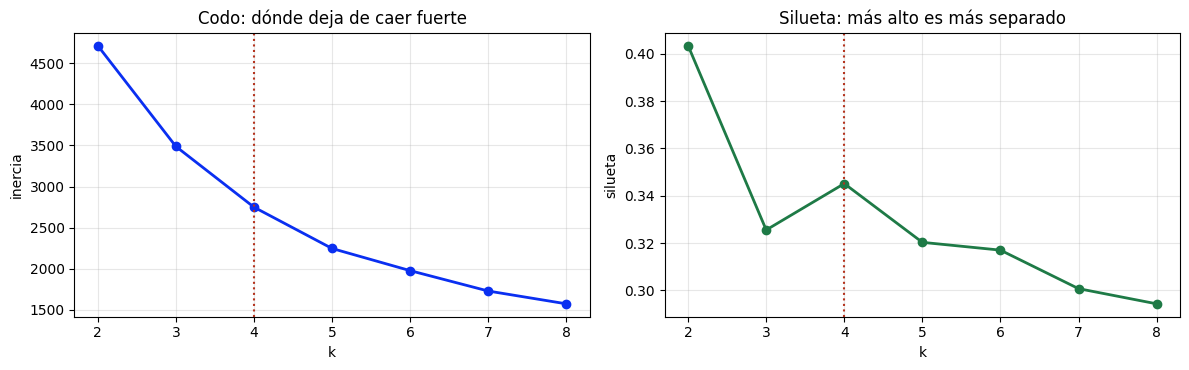

 k  inercia  silueta    caida
 2 4715.080    0.403      NaN
 3 3488.360    0.326 1226.720
 4 2748.661    0.345  739.699
 5 2245.599    0.320  503.062
 6 1975.880    0.317  269.719
 7 1727.512    0.301  248.368
 8 1571.636    0.294  155.876


In [5]:
ks, inercias, siluetas = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(E)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(E, km.labels_))

tabla_k = pd.DataFrame({"k": list(ks), "inercia": inercias, "silueta": siluetas})
tabla_k["caida"] = -tabla_k["inercia"].diff()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.plot(ks, inercias, marker="o", color=AZUL, lw=2)
a1.axvline(4, ls=":", color=ROJO)
a1.set_xlabel("k"); a1.set_ylabel("inercia"); a1.set_title("Codo: dónde deja de caer fuerte")
a2.plot(ks, siluetas, marker="o", color=VERDE, lw=2)
a2.axvline(4, ls=":", color=ROJO)
a2.set_xlabel("k"); a2.set_ylabel("silueta"); a2.set_title("Silueta: más alto es más separado")
plt.tight_layout(); plt.show()

print(tabla_k.round(3).to_string(index=False))

> **Los dos criterios no coinciden, y está bien que no coincidan.**
>
> La **silueta** tiene su máximo en k = 2. Es correcto: dos grupos siempre se separan mejor
> que cuatro. Y es inservible, porque con dos grupos no hay nada que decidir.
>
> El **codo** está en k = 4: la mitad de la mejora total de inercia ocurre entre k = 2 y
> k = 4, y después las caídas se achican.
>
> Desempata el negocio: cuatro campañas es un número que un área comercial puede ejecutar.
> **Elegimos k = 4 porque el indicador lo permite y el negocio lo necesita** — no porque el
> indicador lo diga. Esa distinción va escrita en el informe.

## A5 · Los cuatro segmentos

Ahora sí, el modelo final, y el paso que la mayoría se saltea: **perfilarlos**. Sin perfil, los grupos no se pueden nombrar.

In [6]:
km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(E)
X["segmento"] = km.labels_

perfil = X.groupby("segmento").agg(
    clientes=("monto", "size"),
    recencia=("recencia", "median"),
    compras=("frecuencia", "median"),
    gasto=("monto", "median"),
    ticket=("ticket", "median"),
    categorias=("categorias", "median"),
)
perfil["% base"]  = perfil["clientes"] / len(X) * 100
perfil["% plata"] = X.groupby("segmento")["monto"].sum() / X["monto"].sum() * 100
perfil["churn %"] = churn.groupby(X["segmento"]).mean() * 100

perfil.sort_values("gasto", ascending=False).round(1)

,clientes,recencia,compras,gasto,ticket,categorias,% base,% plata,churn %
segmento,,,,,,,,,
3,658,16.0,13.0,2589649.2,183950.9,5.0,21.5,55.3,12.3
2,1107,81.0,5.0,901214.0,176038.5,3.0,36.1,31.0,51.2
1,459,10.0,4.0,665460.4,149569.1,3.0,15.0,9.6,33.8
0,842,133.0,1.0,155394.4,89953.8,1.0,27.5,4.1,70.7


**Cómo leer esta tabla.** Las columnas de recencia, compras y gasto son **medianas** de cada
grupo, no promedios: con colas largas la mediana describe mejor al cliente típico.

Las dos columnas que más dicen son `% base` y `% plata`. Si un grupo es el 20 % de los
clientes y el 55 % de la facturación, eso es una decisión de presupuesto esperando a ser
tomada.

La columna `churn %` **no entró al modelo**. La agregamos después, solo para ver qué pasó con
cada grupo.

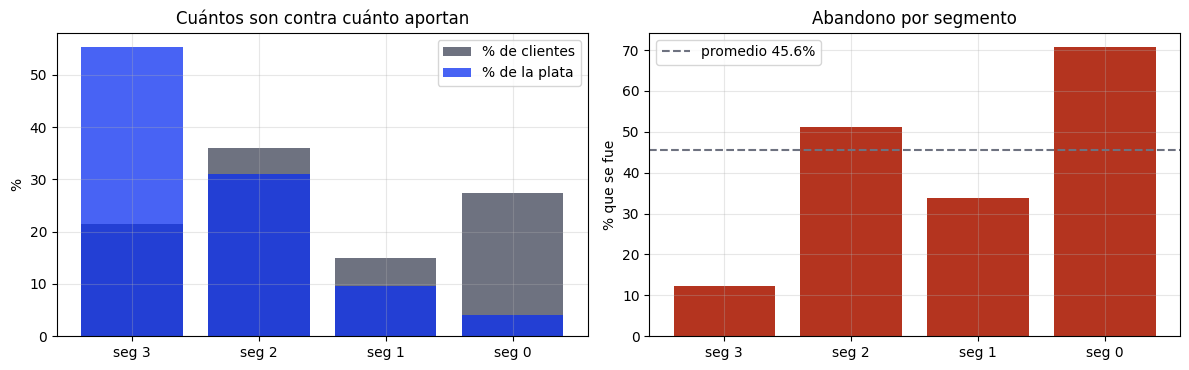

In [7]:
orden = perfil.sort_values("gasto", ascending=False).index

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.bar([f"seg {i}" for i in orden], perfil.loc[orden, "% base"], color=GRIS, label="% de clientes")
a1.bar([f"seg {i}" for i in orden], perfil.loc[orden, "% plata"], color=AZUL, alpha=.75, label="% de la plata")
a1.set_ylabel("%"); a1.legend(); a1.set_title("Cuántos son contra cuánto aportan")

a2.bar([f"seg {i}" for i in orden], perfil.loc[orden, "churn %"], color=ROJO)
a2.axhline(churn.mean() * 100, ls="--", color=GRIS, label=f"promedio {churn.mean():.1%}")
a2.set_ylabel("% que se fue"); a2.legend(); a2.set_title("Abandono por segmento")
plt.tight_layout(); plt.show()

> **Un resultado que no buscábamos.** El modelo nunca vio la columna de abandono, y sin
> embargo los segmentos quedan ordenados por riesgo de punta a punta. Eso pasa porque
> recencia, frecuencia y monto ya contenían esa información.
>
> Ojo con la conclusión de más: esto **no** convierte a K-Means en un modelo de abandono. No
> da una probabilidad por cliente y no se puede evaluar con AUC. Lo que muestra es que esas
> tres variables son buenas, que es justamente lo que vamos a aprovechar la clase que viene.

## A6 · De número a nombre

El entregable no es la columna `segmento`. Es esta tabla.

In [8]:
# Completar con los nombres que surjan del perfil de arriba.
nombres = {
    0: "Una sola compra",
    1: "Nuevos",
    2: "En riesgo",
    3: "Campeones",
}
acciones = {
    0: "Casi ninguna: reactivar cuesta más de lo que aportan",
    1: "Venta cruzada, que prueben una segunda categoría",
    2: "Campaña de retención — acá rinde el presupuesto",
    3: "Fidelización y acceso anticipado, sin descuentos",
}

entregable = perfil.assign(
    nombre=perfil.index.map(nombres),
    accion=perfil.index.map(acciones),
)[["nombre", "clientes", "% base", "% plata", "churn %", "accion"]]

entregable.sort_values("% plata", ascending=False).round(1)

,nombre,clientes,% base,% plata,churn %,accion
segmento,,,,,,
3,Campeones,658,21.5,55.3,12.3,"Fidelización y acceso anticipado, sin descuentos"
2,En riesgo,1107,36.1,31.0,51.2,Campaña de retención — acá rinde el presupuesto
1,Nuevos,459,15.0,9.6,33.8,"Venta cruzada, que prueben una segunda categoría"
0,Una sola compra,842,27.5,4.1,70.7,Casi ninguna: reactivar cuesta más de lo que a...


El cliente típico de cada grupo — esto ES el modelo:

       segmento  recencia  frecuencia     monto  clientes
Una sola compra     119.0         1.0  129763.0       842
         Nuevos       7.0         4.0  607367.0       459
      En riesgo      81.0         5.0  890697.0      1107
      Campeones      13.0        15.0 2707240.0       658

Cada uno de esos cuatro renglones es un centro. Un cliente pertenece
a un grupo si está más cerca de ese centro que de los otros tres.


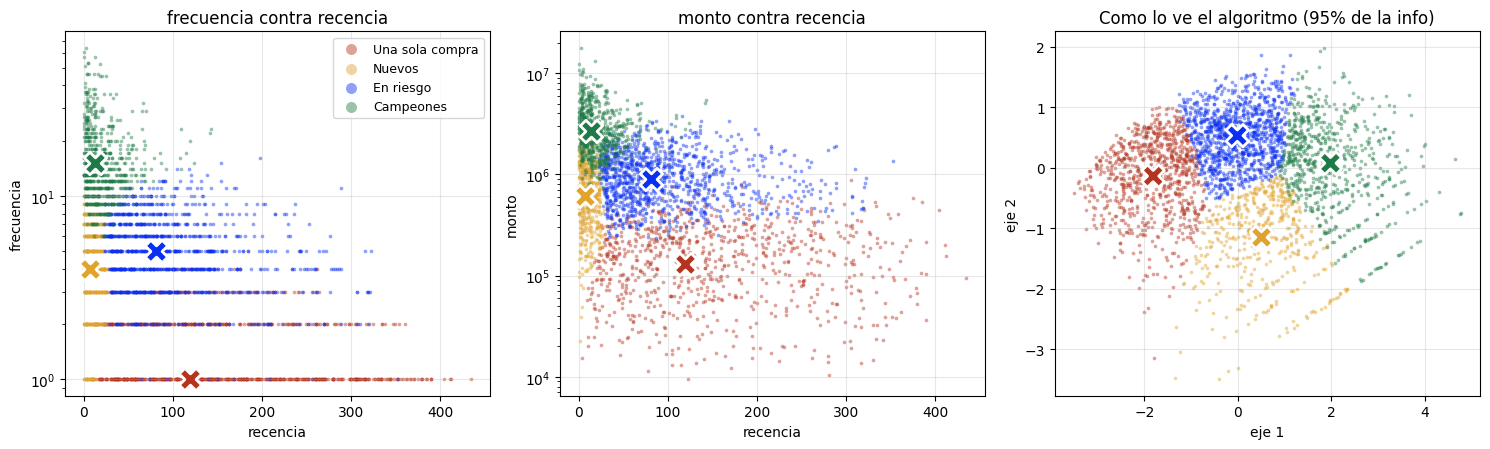

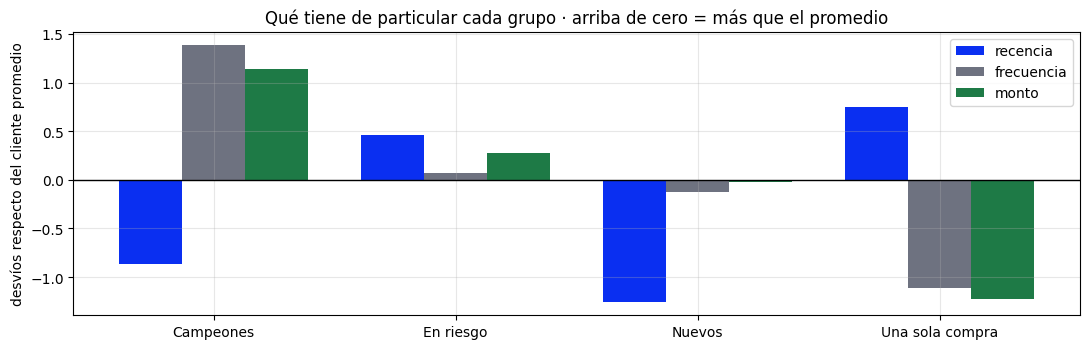


Ojo con la recencia: la barra para ARRIBA significa que hace MÁS
tiempo que no compra. En recencia, más alto es peor.


In [9]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  A7 · Ver el modelo                                              ║
# ║  Hasta acá vimos tablas. Esto es la segmentación dibujada.       ║
# ╚══════════════════════════════════════════════════════════════════╝

from sklearn.decomposition import PCA

COLORES = ["#B4341F", "#E0A32E", "#0A2FF1", "#1E7A46"]
color = lambda s: COLORES[s % len(COLORES)]
etiqueta = {s: nombres.get(s, f"Grupo {s}") for s in sorted(X["segmento"].unique())}

# ── 1. Los centros, en unidades de verdad ──────────────────────────
centros = pd.DataFrame(
    np.expm1(StandardScaler().fit(np.log1p(rfm)).inverse_transform(km.cluster_centers_)),
    columns=rfm.columns,
).round(0)
centros.insert(0, "segmento", [etiqueta[i] for i in range(len(centros))])
centros["clientes"] = X["segmento"].value_counts().sort_index().values

print("El cliente típico de cada grupo — esto ES el modelo:\n")
print(centros.to_string(index=False))
print("\nCada uno de esos cuatro renglones es un centro. Un cliente pertenece")
print("a un grupo si está más cerca de ese centro que de los otros tres.")

# ── 2. Los grupos en el plano ──────────────────────────────────────
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.6))

for ax, (vx, vy) in zip(ejes, [("recencia", "frecuencia"), ("recencia", "monto")]):
    for s in etiqueta:
        m = X["segmento"] == s
        ax.scatter(X.loc[m, vx], X.loc[m, vy], s=7, alpha=.45,
                   color=color(s), label=etiqueta[s], linewidths=0)
    for s in etiqueta:
        ax.scatter(centros.loc[s, vx], centros.loc[s, vy], marker="X", s=260,
                   color=color(s), edgecolor="white", linewidths=2, zorder=5)
    ax.set_xlabel(vx); ax.set_ylabel(vy); ax.set_yscale("log")
    ax.set_title(f"{vy} contra {vx}")

p = PCA(n_components=2).fit(E)
P, Pc = p.transform(E), p.transform(km.cluster_centers_)
for s in etiqueta:
    m = X["segmento"].values == s
    ejes[2].scatter(P[m, 0], P[m, 1], s=7, alpha=.45, color=color(s), linewidths=0)
ejes[2].scatter(Pc[:, 0], Pc[:, 1], marker="X", s=260,
                c=[color(i) for i in range(len(Pc))],
                edgecolor="white", linewidths=2, zorder=5)
ejes[2].set_title(f"Como lo ve el algoritmo ({p.explained_variance_ratio_.sum():.0%} de la info)")
ejes[2].set_xlabel("eje 1"); ejes[2].set_ylabel("eje 2")

ejes[0].legend(markerscale=3, fontsize=9, loc="upper right")
plt.tight_layout(); plt.show()

# ── 3. El perfil de cada grupo, de un vistazo ──────────────────────
perfil_z = pd.DataFrame(km.cluster_centers_, columns=rfm.columns)
perfil_z.index = [etiqueta[i] for i in perfil_z.index]
orden = perfil_z["monto"].sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 3.6))
ancho, pos = 0.26, np.arange(len(orden))
for j, v in enumerate(rfm.columns):
    ax.bar(pos + (j - 1) * ancho, perfil_z.loc[orden, v], ancho,
           label=v, color=[AZUL, GRIS, VERDE][j])
ax.axhline(0, color="k", lw=1)
ax.set_xticks(pos); ax.set_xticklabels(orden)
ax.set_ylabel("desvíos respecto del cliente promedio")
ax.set_title("Qué tiene de particular cada grupo · arriba de cero = más que el promedio")
ax.legend(); plt.tight_layout(); plt.show()

print("\nOjo con la recencia: la barra para ARRIBA significa que hace MÁS")
print("tiempo que no compra. En recencia, más alto es peor.")

---
# Qué sacamos en limpio

## Para qué agrupamos

Nadie puede diseñar 3.066 tratamientos distintos. La segmentación existe para que
una decisión que no se puede tomar cliente por cliente se pueda tomar grupo por
grupo. Pasamos de una base imposible de manejar a cuatro grupos con cuatro
acciones, y eso es todo lo que se le pedía.

Fíjense que el modelo **no predijo nada**. No dijo quién se va a ir, no dio una
probabilidad, no hay acierto que calcular. Y aun así ordenó la base lo suficiente
como para decidir dónde poner la plata. Un modelo que no predice puede ser el más
útil de todos.

## Qué dicen estos cuatro grupos

| Segmento | Clientes | % de la base | % de la plata | Abandono |
|---|---|---|---|---|
| Campeones | 658 | 21,5 % | 55,3 % | 12,3 % |
| Nuevos | 459 | 15,0 % | 9,6 % | 33,8 % |
| En riesgo | 1.107 | 36,1 % | 31,0 % | 51,2 % |
| Una sola compra | 842 | 27,5 % | 4,1 % | 70,7 % |

Lo primero que salta es la concentración, que ya habíamos visto como curva en la
clase de exploración: **una quinta parte de los clientes es más de la mitad de la
facturación**. La diferencia es que antes era un gráfico y ahora es un grupo con
nombre al que se le puede mandar una campaña.

Lo segundo es menos obvio y es la conclusión que importa. **La plata no va al
grupo que más factura ni al que más se va.** A los Campeones no hace falta
retenerlos: se quedan igual, y gastar ahí es pagar por algo que ya iba a pasar.
A los de una sola compra no conviene recuperarlos: aportan cuatro pesos de cada
cien y reactivarlos cuesta más que eso. El presupuesto va a **«En riesgo»**, que
es el único grupo que junta las tres cosas al mismo tiempo: son muchos, dejan
plata, y la mitad se está yendo.

Ese razonamiento —buscar dónde el peso siguiente rinde más, en vez de dónde está
el número más grande— es lo que separa un informe de analista de una planilla.

## Las dos trampas

**Escalar no es opcional.** Sin escalar, los cuatro grupos salieron como cuatro
tramos del monto, uno pegado al otro. El código corrió igual, los gráficos
salieron igual de prolijos y la silueta dio *más alta* que la versión correcta:
0,623 contra 0,345. Es el mismo problema del acierto del 54,4 % de la clase
pasada. **Un número alto no significa un buen modelo.**

**Cuántos grupos no lo decide un indicador.** La silueta decía k = 2 y el codo
decía k = 4. Los dos criterios técnicos sirven para descartar los k absurdos, no
para elegir. Elegimos 4 porque cuatro campañas es lo que una empresa puede
ejecutar. Eso va escrito y justificado en el informe.

## Qué NO es una segmentación

K-Means **siempre** devuelve k grupos. Si le piden cuatro, les da cuatro, incluso
sobre números al azar. Que haya devuelto cuatro no prueba nada por sí solo.

Y los nombres no los puso el algoritmo: el algoritmo devolvió 0, 1, 2 y 3.
«Campeones» lo pusimos nosotros leyendo la tabla de perfiles. Esa parte es
humana, y está bien que lo sea, pero hay que saberlo.

La prueba de que acá sí había estructura es otra: **el abandono nunca entró al
modelo y salió ordenado igual**, 12 % → 34 % → 51 % → 71 %. Si los grupos fueran
un recorte arbitrario, los cuatro tendrían alrededor del 45,6 % que tiene la base
entera. No lo tienen.

Con todo, los clientes no vienen en cuatro tipos. Hay un continuo de
comportamiento y nosotros lo cortamos en cuatro lugares porque nos sirve para
decidir, igual que los deciles de ingreso: nadie nace perteneciendo al decil 7.

## Lo que viene

La segmentación dice **dónde** invertir. La clase que viene vamos a ver cómo
decidir **a quién** llamar dentro de ese grupo, con una regresión logística que
devuelve una probabilidad cliente por cliente — y que sí se puede evaluar contra
una línea de base.

---
# Parte B · Su propio dataset

Lo que sigue corre sobre la tabla de clientes que armaron en la clase 8. Si la guardaron en
un CSV, cárguenla; si no, vuelvan al notebook de esa clase y regenérenla.

**Si su dataset mide en puntaje y no en plata**, reemplacen el monto por la variable de
actividad que hayan construido: cantidad de reseñas, cantidad de calificaciones, lo que
corresponda. El resto no cambia.

In [ ]:
# B = pd.read_csv("mi_tabla_de_clientes.csv", index_col=0)

B = X.drop(columns=["crudo", "segmento"])   # ← reemplazar por SU tabla

VARIABLES = ["recencia", "frecuencia", "monto"]   # ← ajustar a SUS columnas

B = B[VARIABLES].dropna()
print(f"Clientes: {len(B):,}")
print(B.describe().loc[["min", "50%", "max"]].round(1).to_string())

Clientes: 3,066
     recencia  frecuencia       monto
min       0.0         1.0      9460.6
50%      55.0         4.0    749971.2
max     434.0        64.0  17745860.2


> **Antes de seguir, dos controles.**
>
> Si alguna variable tiene valores negativos, el `log1p` va a fallar: decidan qué hacer con
> ellos y anótenlo en la bitácora.
>
> Si una variable tiene menos de cinco valores distintos, no aporta a una segmentación por
> distancias. Sáquenla.

## B1 · Preparar y elegir k

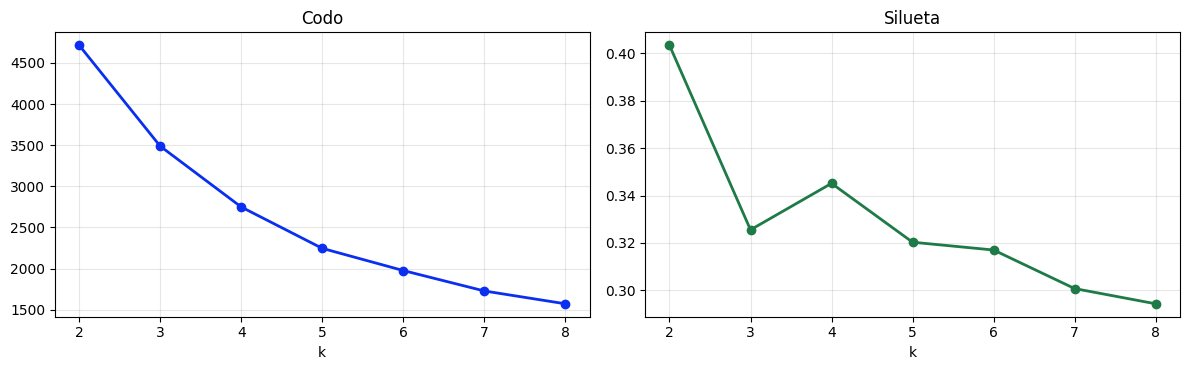

 k  inercia  silueta    caida
 2 4715.080    0.403      NaN
 3 3488.360    0.326 1226.720
 4 2748.661    0.345  739.699
 5 2245.599    0.320  503.062
 6 1975.880    0.317  269.719
 7 1727.512    0.301  248.368
 8 1571.636    0.294  155.876


In [ ]:
EB = StandardScaler().fit_transform(np.log1p(B))

ks, inB, siB = range(2, 9), [], []
for k in ks:
    kmB = KMeans(n_clusters=k, random_state=42, n_init=10).fit(EB)
    inB.append(kmB.inertia_)
    siB.append(silhouette_score(EB, kmB.labels_))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.plot(ks, inB, marker="o", color=AZUL, lw=2); a1.set_xlabel("k"); a1.set_title("Codo")
a2.plot(ks, siB, marker="o", color=VERDE, lw=2); a2.set_xlabel("k"); a2.set_title("Silueta")
plt.tight_layout(); plt.show()

resB = pd.DataFrame({"k": list(ks), "inercia": inB, "silueta": siB})
resB["caida"] = -resB["inercia"].diff()
print(resB.round(3).to_string(index=False))

> **Si el codo y la silueta no coinciden** —lo más probable— elijan igual y escriban el
> argumento. Esa justificación vale más en el informe que el k que elijan.
>
> **Si la silueta da por debajo de 0,20 en todos los k**, sus clientes no forman grupos
> naturales. No está mal: significa que la base es homogénea. Dígalo en el informe, es un
> hallazgo. Lo que no se puede es inventar cuatro grupos y hablar de ellos como si existieran.

## B2 · Segmentar, perfilar y nombrar

In [ ]:
K = 4   # ← el que decidieron arriba

kmB = KMeans(n_clusters=K, random_state=42, n_init=10).fit(EB)
B["segmento"] = kmB.labels_

perfilB = B.groupby("segmento").median()
perfilB["clientes"] = B.groupby("segmento").size()
perfilB["% base"] = perfilB["clientes"] / len(B) * 100
if "monto" in VARIABLES:
    perfilB["% plata"] = B.groupby("segmento")["monto"].sum() / B["monto"].sum() * 100

perfilB.round(1)

,recencia,frecuencia,monto,clientes,% base,% plata
segmento,,,,,,
0,133.0,1.0,155394.4,842,27.5,4.1
1,10.0,4.0,665460.4,459,15.0,9.6
2,81.0,5.0,901214.0,1107,36.1,31.0
3,16.0,13.0,2589649.2,658,21.5,55.3


## B3 · El entregable

Completen esta tabla y guárdenla: **es la sección de segmentación del trabajo final.**

| Segmento | Nombre | Clientes | % base | % actividad | Perfil en una línea | Acción |
|---|---|---|---|---|---|---|
| 0 | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

Tres reglas para los nombres:

- En el idioma del negocio, no del algoritmo. «Compradores de temporada» sí, «grupo 2» no.
- Que se entiendan sin ver la tabla.
- Una acción concreta por grupo. **Vale decir «ninguna»**, con el número que lo justifique.

---
### Para la clase que viene

Subir a Classroom la tabla de segmentos con nombre, perfil y acción, y dejar guardada la
tabla de clientes con la columna `segmento` agregada.

Y traer una hipótesis: **¿qué variable creen que más predice el abandono en su dataset?**
La vamos a anotar en el pizarrón el 30/10 y compararla con los coeficientes reales.